# Structural characteristics of AI agent skills (RQ1)

**Study:** *Understanding the Structure and Reuse of AI Agent Skills in Open-Source Software Projects: An Empirical Study*  
**Data:** GitSkills sample (July 2026)  
**Research question:** What are the structural characteristics of AI agent skills in open-source software repositories?

This analysis describes the structure of distinct `SKILL.md` contents in the GitSkills sample. We measure instruction length, YAML front matter validity, and the supporting files recorded alongside each selected skill. The analysis also produces Figure 1 for the manuscript.

The source database is `data/raw/agent_skills_sample.db`. Figures are written to `figures/rq1_structural_characteristics.pdf` and `.png`. The notebook can be executed independently of the other analyses.


## 1. Database connection

The database is opened in read-only mode. The path resolution supports launching Jupyter from either the project root or its `notebooks` directory. The expected database location is `data/raw/agent_skills_sample.db` relative to the project root.


In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
candidates = [cwd, cwd.parent]
PROJECT_ROOT = next((p for p in candidates if (p / "data/raw/agent_skills_sample.db").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Expected data/raw/agent_skills_sample.db under the project root; start Jupyter from the project or notebooks directory.")
DB_PATH = PROJECT_ROOT / "data" / "raw" / "agent_skills_sample.db"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
conn = sqlite3.connect(DB_PATH.as_uri() + "?mode=ro", uri=True)
print("Database:", DB_PATH)
print("Figure directory:", FIGURES_DIR)

Database: C:\Users\mouzh\Documents\GitHub\MSR2027-GitSkills\data\raw\agent_skills_sample.db
Figure directory: C:\Users\mouzh\Documents\GitHub\MSR2027-GitSkills\figures


## 2. Selecting distinct contents

The `artifacts` table records individual occurrences of skill files. Multiple occurrences can have the same `file_sha` when their contents are identical. To avoid counting repeated contents more than once, we use the record marked `dedup_primary = 1` for each hash. This gives 13,000 distinct contents for RQ1.

There is an important distinction between the instruction file and its surrounding folder. Two repositories can contain identical `SKILL.md` contents but different scripts or reference files. The composition fields therefore describe the folder of the selected representative, not every occurrence of that content.


In [2]:
structure_df = pd.read_sql_query("""
SELECT file_sha, repo_full_name, name, description, body_chars,
       frontmatter_valid, sibling_count, sibling_bytes,
       has_scripts, has_references, composition_fetched
FROM artifacts
WHERE dedup_primary = 1
""", conn)

print("Primary representative rows:", len(structure_df))
print("Distinct hashes:", structure_df["file_sha"].nunique())
assert len(structure_df) == structure_df["file_sha"].nunique(), "More than one representative for a hash"
assert len(structure_df) == 13_000, "Unexpected GitSkills sample size"
display(structure_df.head(5))

Primary representative rows: 13000
Distinct hashes: 13000


,file_sha,repo_full_name,name,description,body_chars,frontmatter_valid,sibling_count,sibling_bytes,has_scripts,has_references,composition_fetched
0,00000818feedfd1e1d22f6bb42362f0c4e5213e4,alas-poor-ophelia/windrose-md,NaN,NaN,9848,0,0.0,0.0,0.0,0.0,1
1,000009fe40ffb92ccb4350995d114f838be78237,etendosoftware/etendo_schema_forge,testing-delivery-gate,"Use when closing, preparing, reviewing, or doc...",6528,1,0.0,0.0,0.0,0.0,1
2,00000f2a9d8359900f2075b536b435ca9473a5b9,obot-platform/obot,draft-release-blog,Draft a release announcement blog post for an ...,13056,1,1.0,1158.0,1.0,0.0,1
3,000011cf09114922342962431de29bea54807b28,Klotzkette/claude-fuer-deutsches-recht,fachanwalt-gewerblicher-rechtsschutz-uwg-einst...,Wenn es um UWG-Einstweilige Verfuegung in Fach...,6860,1,0.0,0.0,0.0,0.0,1
4,000015349a0cc3fe71d881963d9a151363efd447,OTOJulian/oto-hybrid-framework,writing-skills,"Use when creating new skills, editing existing...",22367,1,6.0,80528.0,1.0,1.0,1


## 3. Completeness of structural attributes

Before calculating descriptive statistics, we check how many records have values for each structural attribute. Missing composition values are excluded from the relevant calculation rather than treated as zero. This matters particularly for supporting-file prevalence, where a missing value does not establish that no supporting files exist.

The sample was selected by content hash, so the resulting percentages describe the selected contents rather than a random sample of GitHub repositories.


In [3]:
structural_columns = ["body_chars", "frontmatter_valid", "sibling_count", "sibling_bytes",
                      "has_scripts", "has_references", "composition_fetched"]
completeness_df = pd.DataFrame({
    "Available": structure_df[structural_columns].notna().sum(),
    "Missing": structure_df[structural_columns].isna().sum(),
    "Available (%)": (100 * structure_df[structural_columns].notna().mean()).round(2)
})
display(completeness_df)
assert structure_df["body_chars"].notna().sum() == 13_000
assert structure_df["sibling_count"].notna().sum() == 12_990

,Available,Missing,Available (%)
body_chars,13000,0,100.00
frontmatter_valid,13000,0,100.00
sibling_count,12990,10,99.92
sibling_bytes,12990,10,99.92
has_scripts,12990,10,99.92
has_references,12990,10,99.92
composition_fetched,13000,0,100.00


## 4. Instruction length and supporting-file quantities

`body_chars` is the length of the instruction body in characters. It does not measure the size of the complete skill folder. The `sibling_count` and `sibling_bytes` fields describe the number and recorded size of accompanying files for the representative occurrence.

We report the mean, median, and selected percentiles to capture both typical values and the long upper tails of these distributions. All observations remain in the summary statistics, including the largest values.


In [4]:
numeric_columns = ["body_chars", "sibling_count", "sibling_bytes"]
structure_summary = structure_df[numeric_columns].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T
display(structure_summary)
assert int(structure_df["body_chars"].median()) == 4_493
assert int(structure_df["body_chars"].max()) == 211_535

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
body_chars,13000.0,6815.793231,8.466102e+03,0.0,2088.75,4493.0,8614.50,14646.8,20181.5,40524.43,211535.0
sibling_count,12990.0,3.650269,4.578075e+01,0.0,0.00,0.0,1.00,5.0,9.0,50.00,3218.0
sibling_bytes,12990.0,96631.523172,2.204185e+06,0.0,0.00,0.0,2404.75,23481.4,62355.7,692664.83,176657869.0


## 5. Prevalence of structural features

We use `frontmatter_valid` to identify valid YAML front matter, `sibling_count > 0` to identify folders with supporting files, and the recorded `has_scripts` and `has_references` flags for the other two features.

Each percentage is calculated over records with an available value for that attribute. The categories overlap: a representative folder may contain both scripts and references.


In [5]:
feature_results = []
for col in ["frontmatter_valid", "has_scripts", "has_references"]:
    valid = structure_df[col].dropna()
    feature_results.append({
        "Feature": col,
        "Available records": len(valid),
        "Positive records": int((valid == 1).sum()),
        "Positive (%)": round(100 * (valid == 1).mean(), 2)
    })
siblings = structure_df["sibling_count"].dropna()
feature_results.append({
    "Feature": "has_supporting_files",
    "Available records": len(siblings),
    "Positive records": int((siblings > 0).sum()),
    "Positive (%)": round(100 * (siblings > 0).mean(), 2)
})
feature_prevalence_df = pd.DataFrame(feature_results)
display(feature_prevalence_df)
expected = {"frontmatter_valid": 86.85, "has_supporting_files": 34.33,
            "has_references": 23.53, "has_scripts": 10.21}
for feature, target in expected.items():
    actual = feature_prevalence_df.set_index("Feature").loc[feature, "Positive (%)"]
    assert abs(actual - target) < 0.011, f"{feature}: {actual} != {target}"

,Feature,Available records,Positive records,Positive (%)
0,frontmatter_valid,13000,11291,86.85
1,has_scripts,12990,1326,10.21
2,has_references,12990,3057,23.53
3,has_supporting_files,12990,4460,34.33


## 6. Composition coverage and unusual values

Composition information was fetched for 12,990 of the 13,000 primary representatives. We inspect the fetch status and the largest recorded folders to see how extreme values affect the distributions. These records are retained in the analysis.

Some directory listings were truncated during collection. The relationship between the truncation flag and recorded supporting-file counts is examined separately in Notebook 02; the flag alone does not establish that a count is wrong.


In [6]:
print("Composition fetched status:")
display(structure_df["composition_fetched"].value_counts(dropna=False).rename_axis("status").to_frame("contents"))
print("Zero-length instruction bodies:", int((structure_df["body_chars"] == 0).sum()))
print("Missing descriptions:", int(structure_df["description"].isna().sum()))
print("Top 10 representative folders by supporting-file count:")
display(structure_df[["repo_full_name", "name", "body_chars", "sibling_count", "sibling_bytes"]]
        .sort_values("sibling_count", ascending=False).head(10))

Composition fetched status:


,contents
status,
1,12990
0,10


Zero-length instruction bodies: 1
Missing descriptions: 1560
Top 10 representative folders by supporting-file count:


,repo_full_name,name,body_chars,sibling_count,sibling_bytes
10052,MichelKerkmeester/opencode--skilled-agent-loop...,system-spec-kit,36490,3218.0,30267948.0
2388,huangwenxuangod/flash-recorder,NaN,2169,2542.0,83587579.0
3114,samouraiworld/memba,NaN,6066,1760.0,15418448.0
830,agisota/rox,oh-my-claudecode,522,1362.0,13602051.0
6604,thtang/alpha-persona-lab,yutinghao,11886,925.0,18374366.0
3193,mpsuesser/workspace,oxlint,6460,779.0,1108677.0
6311,asd1702/todongsan,NaN,1497,645.0,3195208.0
5879,controlplane-docs/docs,cpln,40102,562.0,13142175.0
3824,EvoMap/evolver,capability-evolver,5642,454.0,13876325.0
9184,ankushKun/pumpmyclaw,NaN,14645,447.0,12514042.0


## 7. Distribution of supporting-file counts

We group the 12,990 representatives with fetched composition data by their number of accompanying files. The groups are mutually exclusive, and missing composition records are not included in the denominator.

This provides a more detailed view of folder composition than the overall percentage with supporting files, including the proportion of representative folders containing no additional files.


In [7]:
composition_df = structure_df.loc[structure_df["composition_fetched"] == 1].copy()
composition_df["sibling_category"] = pd.cut(
    composition_df["sibling_count"],
    bins=[-1, 0, 1, 5, 10, 50, float("inf")],
    labels=["0 files", "1 file", "2–5 files", "6–10 files", "11–50 files", ">50 files"]
)
composition_distribution_df = (composition_df.groupby("sibling_category", observed=False)
                               .size().reset_index(name="skills"))
composition_distribution_df["percentage"] = (100 * composition_distribution_df["skills"] /
                                             len(composition_df)).round(2)
display(composition_distribution_df)
assert len(composition_df) == 12_990
assert int(composition_distribution_df["skills"].sum()) == 12_990
assert int(composition_distribution_df.iloc[0]["skills"]) == 8_530

,sibling_category,skills,percentage
0,0 files,8530,65.67
1,1 file,1799,13.85
2,2–5 files,1528,11.76
3,6–10 files,559,4.30
4,11–50 files,446,3.43
5,>50 files,128,0.99


## 8. Figure 1: structural characteristics

The left panel shows instruction-body lengths. Values above the 99th percentile are omitted **only from the histogram**, allowing the main part of the distribution to remain legible; they are still included in the descriptive statistics. The right panel compares the prevalence of valid front matter, supporting files, references, and scripts using the available observations for each feature.

The figure is saved as a vector PDF for the manuscript and a PNG for inspection.


Saved: C:\Users\mouzh\Documents\GitHub\MSR2027-GitSkills\figures\rq1_structural_characteristics.pdf
Saved: C:\Users\mouzh\Documents\GitHub\MSR2027-GitSkills\figures\rq1_structural_characteristics.png


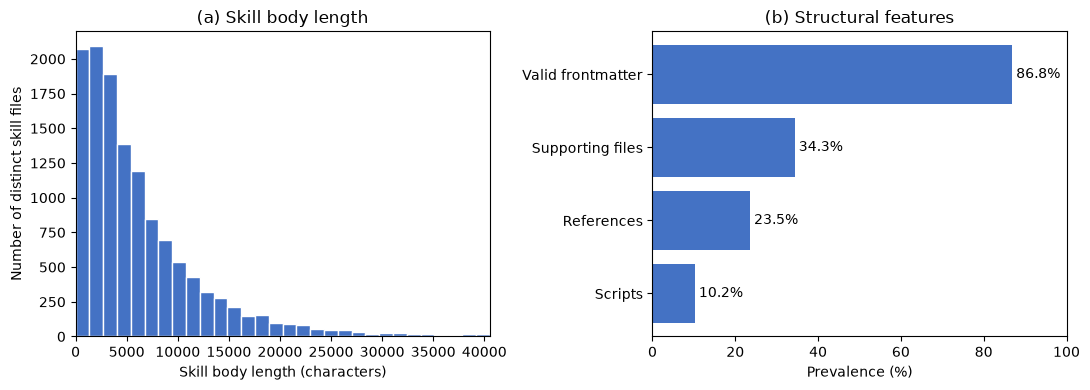

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

body_lengths = structure_df["body_chars"].dropna()
upper_limit = body_lengths.quantile(0.99)
filtered_lengths = body_lengths[body_lengths <= upper_limit]
axes[0].hist(filtered_lengths, bins=30, color="#4472C4", edgecolor="white")
axes[0].set_xlim(0, upper_limit)
axes[0].set_xlabel("Skill body length (characters)")
axes[0].set_ylabel("Number of distinct skill files")
axes[0].set_title("(a) Skill body length")

feature_order = ["frontmatter_valid", "has_supporting_files", "has_references", "has_scripts"]
feature_labels = ["Valid frontmatter", "Supporting files", "References", "Scripts"]
feature_values = (feature_prevalence_df.set_index("Feature")
                  .loc[feature_order, "Positive (%)"].tolist())
axes[1].barh(feature_labels, feature_values, color="#4472C4")
axes[1].invert_yaxis()
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Prevalence (%)")
axes[1].set_title("(b) Structural features")
for i, value in enumerate(feature_values):
    axes[1].text(value + 1, i, f"{value:.1f}%", va="center")

fig.tight_layout()
for extension, options in [("pdf", {}), ("png", {"dpi": 300})]:
    out = FIGURES_DIR / f"rq1_structural_characteristics.{extension}"
    fig.savefig(out, bbox_inches="tight", **options)
    print("Saved:", out)
plt.show()

## 9. Checks against the reported results

The assertions below compare the calculated values with those reported for this GitSkills snapshot. They are intended to catch changes in the database, filters, or analysis code that would otherwise go unnoticed.

Passing these checks confirms agreement with the recorded study results; it does not independently validate how GitSkills collected the original data or establish that the sample represents all open-source repositories.


In [9]:
assert len(structure_df) == 13_000
assert int((structure_df["frontmatter_valid"] == 1).sum()) == 11_291
assert int((structure_df["sibling_count"] > 0).sum()) == 4_460
assert int((structure_df["has_references"] == 1).sum()) == 3_057
assert int((structure_df["has_scripts"] == 1).sum()) == 1_326
assert round(float(structure_df["body_chars"].mean()), 2) == 6815.79
print("All RQ1 manuscript consistency checks passed.")

All RQ1 manuscript consistency checks passed.


## 10. Findings and limitations

The median instruction body is **4,493 characters**, and **86.85%** of the 13,000 distinct contents have valid YAML front matter. Among the **12,990** representatives with composition information, **34.33%** have at least one supporting file, **23.53%** include references, and **10.21%** include scripts. Conversely, **65.67%** have no recorded supporting files.

These figures describe distinct instruction contents rather than all their repository occurrences. Supporting-file measurements refer to the selected representative folders, which may differ from other folders containing identical instructions. The hash-based sample and the original GitHub search coverage also limit how broadly these findings can be generalized.


In [10]:
conn.close()
print("Read-only SQLite connection closed.")

Read-only SQLite connection closed.
